# The second Model
**Specs:** Yolov26s-seg
<br>
**Cons**: The model dataset has 100% more instances of clean_path than the obstacle class

## Installing the Dependencies

In [ ]:
pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.3/41.3 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 73.9 MB/s eta 0:00:00


## Getting the dataset and processing it accordingly
The ndjson file, few of the images, clean path isnt annoted because it was getting too tedious to segment. i am marking everything not annoted to clean_path class. it does add a bit of error though.
rest of the classes in a small subset of data also has wall, ceiling, and obstacles.

In [ ]:
import json
import requests
from pathlib import Path
from tqdm import tqdm

NDJSON_FILE = "/content/drive/MyDrive/IGVC_dataset_ISRO/Self_annoted/isro.ndjson"

SAVE_DIR = "/content/drive/MyDrive/IGVC_dataset_ISRO/Self_annoted_yolo"
Path(SAVE_DIR).mkdir(parents=True, exist_ok=True)

with open(NDJSON_FILE, "r") as f:

    next(f)  # skip metadata line

    lines = f.readlines()

for line in tqdm(lines):

    data = json.loads(line)

    filename = data["file"]
    url = data["url"]

    try:
        response = requests.get(url, timeout=30)

        if response.status_code == 200:
            with open(f"{SAVE_DIR}/{filename}", "wb") as img_file:
                img_file.write(response.content)

    except Exception as e:
        print(f"Failed: {filename} -> {e}")

print("Done")

100%|██████████| 151/151 [01:23<00:00,  1.82it/s]

Done


## Converting to binary masks

In [ ]:
import numpy as np
import cv2
import os
from pathlib import Path

# Define your original class IDs (adjust based on your actual mask values)
original_classes = {
    "wall": 0,
    "clean_path": 1,
    "Obstacle": 2,
    "ceiling": 3,
}

# Define the remapping
# 0 = obstacle (wall + obstacle)
# 1 = clean_path
# 255 = ignore (ceiling) — common convention for "ignore" in segmentation
class_mapping = {
    original_classes["wall"]: 0,
    original_classes["Obstacle"]: 0,
    original_classes["clean_path"]: 1,
    original_classes["ceiling"]: 255,  # ignore label
}

def remap_mask(mask, mapping):
    """Remap mask pixel values according to the mapping dict."""
    remapped = np.full_like(mask, 255)  # default to ignore for any unmapped value
    for old_val, new_val in mapping.items():
        remapped[mask == old_val] = new_val
    return remapped

input_dir = Path("drive/MyDrive/IGVC_dataset_ISRO/additional_dataset/raw/masks")
output_dir = Path("drive/MyDrive/IGVC_dataset_ISRO/additional_dataset/raw/masks_binary")
output_dir.mkdir(parents=True, exist_ok=True)

# --- Process every mask in the folder ---
image_extensions = (".png", ".jpg", ".jpeg")

for mask_path in input_dir.iterdir():
    if mask_path.suffix.lower() not in image_extensions:
        continue

    mask = cv2.imread(str(mask_path), cv2.IMREAD_UNCHANGED)
    if mask is None:
        print(f"Skipping unreadable file: {mask_path.name}")
        continue

    new_mask = remap_mask(mask, class_mapping)

    out_path = output_dir / mask_path.name
    cv2.imwrite(str(out_path), new_mask)

print(f"Done! Processed masks saved to: {output_dir}")

Done! Processed masks saved to: drive/MyDrive/IGVC_dataset_ISRO/additional_dataset/raw/masks_binary


## Converting masks to yolo format
not augmenting data this time

In [ ]:
import cv2
import numpy as np
from pathlib import Path

# ============================================================
# STEP 0: PATHS — adjust these to your folder structure
# ============================================================
raw_masks_dir   = Path("drive/MyDrive/IGVC_dataset_ISRO/additional_dataset/raw/masks")
binary_masks_dir = Path("drive/MyDrive/IGVC_dataset_ISRO/additional_dataset/raw/masks_binary")
labels_dir      = Path("drive/MyDrive/IGVC_dataset_ISRO/additional_dataset/raw/labels")

binary_masks_dir.mkdir(parents=True, exist_ok=True)
labels_dir.mkdir(parents=True, exist_ok=True)

image_extensions = (".png", ".jpg", ".jpeg")

# ============================================================
# STEP 1: CLASS REMAPPING
# Map original class IDs -> new binary class IDs
# Anything NOT listed here automatically becomes 255 (ignore)
# ============================================================
class_mapping = {
    0: 0,  # wall       -> class 0 (wall_obstacle)
    1: 0,  # obstacle   -> class 0 (wall_obstacle)
    2: 1,  # clean_path -> class 1 (clean_path)
    # 3 (ceiling) and anything else -> automatically 255 (ignore)
}

def remap_mask(mask, mapping):
    """Remap mask pixel values. Anything not in mapping -> 255 (ignore)."""
    remapped = np.full_like(mask, 255)
    for old_val, new_val in mapping.items():
        remapped[mask == old_val] = new_val
    return remapped


# ============================================================
# STEP 2: MASK -> POLYGON CONVERSION (YOLO-seg format)
# ============================================================
target_classes = [0, 1]   # class IDs to extract polygons for (255=ignore is skipped)
MIN_AREA = 20              # filter out tiny noise blobs

def mask_to_polygons(mask, class_id, img_w, img_h):
    """Extract normalized polygon points for a given class_id from the mask."""
    binary = np.where(mask == class_id, 255, 0).astype(np.uint8)

    contours, _ = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    polygons = []
    for cnt in contours:
        if cv2.contourArea(cnt) < MIN_AREA:
            continue

        epsilon = 0.001 * cv2.arcLength(cnt, True)
        cnt = cv2.approxPolyDP(cnt, epsilon, True)

        if len(cnt) < 3:
            continue

        norm_points = []
        for point in cnt.reshape(-1, 2):
            x, y = point
            norm_points.append(x / img_w)
            norm_points.append(y / img_h)

        polygons.append(norm_points)

    return polygons


# ============================================================
# STEP 3: RUN THE FULL PIPELINE
# ============================================================
processed = 0
skipped = 0

for mask_path in raw_masks_dir.iterdir():
    if mask_path.suffix.lower() not in image_extensions:
        continue

    # --- Load mask ---
    mask = cv2.imread(str(mask_path), cv2.IMREAD_UNCHANGED)
    if mask is None:
        print(f"Skipping unreadable file: {mask_path.name}")
        skipped += 1
        continue

    # --- Ensure single-channel ---
    if len(mask.shape) == 3:
        mask = mask[:, :, 0]  # take one channel (assumes channels are identical)

    # --- Remap classes ---
    new_mask = remap_mask(mask, class_mapping)

    # --- Save binary remapped mask ---
    out_mask_path = binary_masks_dir / mask_path.name
    cv2.imwrite(str(out_mask_path), new_mask)

    # --- Convert to YOLO polygon labels ---
    img_h, img_w = new_mask.shape[:2]
    label_lines = []
    for class_id in target_classes:
        polygons = mask_to_polygons(new_mask, class_id, img_w, img_h)
        for poly in polygons:
            coords_str = " ".join(f"{c:.6f}" for c in poly)
            label_lines.append(f"{class_id} {coords_str}")

    txt_filename = mask_path.stem + ".txt"
    out_txt_path = labels_dir / txt_filename
    with open(out_txt_path, "w") as f:
        f.write("\n".join(label_lines))

    processed += 1

print(f"Done! Processed: {processed}, Skipped: {skipped}")
print(f"Binary masks saved to: {binary_masks_dir}")
print(f"Labels saved to: {labels_dir}")

Done! Processed: 147, Skipped: 0
Binary masks saved to: drive/MyDrive/IGVC_dataset_ISRO/additional_dataset/raw/masks_binary
Labels saved to: drive/MyDrive/IGVC_dataset_ISRO/additional_dataset/raw/labels


## Checking if change is correct

In [ ]:
# Check a sample binary mask
sample = cv2.imread(str(binary_masks_dir / "real_time_03_jpg.rf.bc26539017224b779307c34f84ee1655.png"), cv2.IMREAD_UNCHANGED)
print("Mask shape:", sample.shape)          # should be (H, W) — single channel
print("Unique values:", np.unique(sample))  # should be [0, 1, 255] (or subset)

# Check a sample label file
with open(labels_dir / "real_time_03_jpg.rf.bc26539017224b779307c34f84ee1655.txt") as f:
    content = f.read()
    print(content[:300] if content else "Empty file (no objects detected)")

Mask shape: (1024, 1024)
Unique values: [0]
0 0.000000 0.000000 0.000000 0.999023 0.999023 0.999023 0.999023 0.000000


In [ ]:
import cv2
import numpy as np
from pathlib import Path

# ============================================================
# PATHS
# ============================================================
raw_masks_dir    = Path("drive/MyDrive/IGVC_dataset_ISRO/additional_dataset/raw/masks")
binary_masks_dir = Path("drive/MyDrive/IGVC_dataset_ISRO/additional_dataset/raw/masks_binary")
labels_dir       = Path("drive/MyDrive/IGVC_dataset_ISRO/additional_dataset/raw/labels")

binary_masks_dir.mkdir(parents=True, exist_ok=True)
labels_dir.mkdir(parents=True, exist_ok=True)

image_extensions = (".png", ".jpg", ".jpeg")

# ============================================================
# COLOR MAPPING (BGR, since cv2 loads as BGR)
# Update these tuples after running Step 1 if they differ!
# ============================================================
color_mapping = {
    (0, 255, 0):   0,   # green -> clean_path -> class 0
    (255, 255, 0): 1,   # cyan  -> wall/obstacle -> class 1
    # black (0,0,0) and anything else -> 255 (ignore)
}

target_classes = [0, 1]
MIN_AREA = 20

def remap_mask_color(mask, mapping, tolerance=10):
    h, w = mask.shape[:2]
    remapped = np.full((h, w), 255, dtype=np.uint8)
    for color, class_id in mapping.items():
        color_arr = np.array(color, dtype=np.int16)
        diff = np.abs(mask.astype(np.int16) - color_arr)
        match = np.all(diff <= tolerance, axis=-1)
        remapped[match] = class_id
    return remapped

def mask_to_polygons(mask, class_id, img_w, img_h):
    binary = np.where(mask == class_id, 255, 0).astype(np.uint8)
    contours, _ = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    polygons = []
    for cnt in contours:
        if cv2.contourArea(cnt) < MIN_AREA:
            continue
        epsilon = 0.001 * cv2.arcLength(cnt, True)
        cnt = cv2.approxPolyDP(cnt, epsilon, True)
        if len(cnt) < 3:
            continue

        norm_points = []
        for point in cnt.reshape(-1, 2):
            x, y = point
            norm_points.append(x / img_w)
            norm_points.append(y / img_h)
        polygons.append(norm_points)

    return polygons


# ============================================================
# RUN PIPELINE
# ============================================================
processed, skipped = 0, 0

for mask_path in raw_masks_dir.iterdir():
    if mask_path.suffix.lower() not in image_extensions:
        continue

    mask = cv2.imread(str(mask_path), cv2.IMREAD_UNCHANGED)
    if mask is None:
        print(f"Skipping unreadable file: {mask_path.name}")
        skipped += 1
        continue

    if mask.ndim == 3 and mask.shape[-1] == 4:
        mask = mask[:, :, :3]  # drop alpha if present

    # --- Color-based remap ---
    new_mask = remap_mask_color(mask, color_mapping, tolerance=10)

    # --- Save binary mask ---
    cv2.imwrite(str(binary_masks_dir / mask_path.name), new_mask)

    # --- Generate YOLO polygon labels ---
    img_h, img_w = new_mask.shape[:2]
    label_lines = []
    for class_id in target_classes:
        for poly in mask_to_polygons(new_mask, class_id, img_w, img_h):
            coords_str = " ".join(f"{c:.6f}" for c in poly)
            label_lines.append(f"{class_id} {coords_str}")

    with open(labels_dir / (mask_path.stem + ".txt"), "w") as f:
        f.write("\n".join(label_lines))

    processed += 1

print(f"Done! Processed: {processed}, Skipped: {skipped}")

Done! Processed: 147, Skipped: 0


Shape: (1024, 1024)
Unique: [  0 255]
0 0.280273 0.421875 0.288086 0.421875 0.289062 0.420898 0.296875 0.420898 0.297852 0.419922 0.305664 0.419922 0.300781 0.419922 0.299805 0.418945 0.284180 0.418945 0.283203 0.419922 0.282227 0.419922
0 0.430664 0.407227 0.431641 0.407227 0.432617 0.408203 0.434570 0.408203 0.435547 0.407227 0.436523


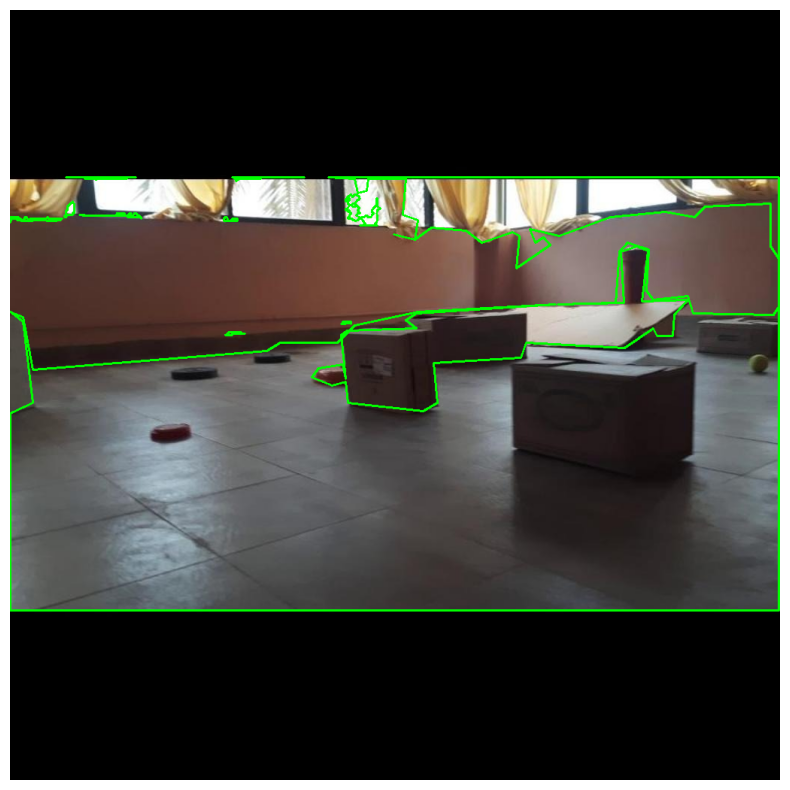

In [ ]:
sample_mask = cv2.imread(str(binary_masks_dir / "real_time_03_jpg.rf.bc26539017224b779307c34f84ee1655.png"), cv2.IMREAD_UNCHANGED)
print("Shape:", sample_mask.shape)        # (1024, 1024) - single channel
print("Unique:", np.unique(sample_mask)) # [0, 1, 255]

with open(labels_dir / "real_time_03_jpg.rf.bc26539017224b779307c34f84ee1655.txt") as f:
    print(f.read()[:300])

import matplotlib.pyplot as plt

def visualize_label(image_path, label_path):
    img = cv2.imread(image_path)
    h, w = img.shape[:2]

    with open(label_path) as f:
        for line in f:
            parts = line.strip().split()
            if not parts:
                continue
            cls_id = int(parts[0])
            coords = np.array(list(map(float, parts[1:]))).reshape(-1, 2)
            coords[:, 0] *= w
            coords[:, 1] *= h
            pts = coords.astype(np.int32)

            color = (0, 255, 0) if cls_id == 0 else (0, 0, 255)
            cv2.polylines(img, [pts], isClosed=True, color=color, thickness=2)

    plt.figure(figsize=(10, 10))
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.show()

visualize_label(
    "drive/MyDrive/IGVC_dataset_ISRO/additional_dataset/raw/images/real_time_03_jpg.rf.bc26539017224b779307c34f84ee1655.jpg",  # adjust extension/name as needed
    str(labels_dir / "real_time_03_jpg.rf.bc26539017224b779307c34f84ee1655.txt")
)

## Training the model

In [ ]:
pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.3/41.3 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 22.4 MB/s eta 0:00:00


## Adding the previous data and current data to one folder

In [ ]:
import shutil, random
from pathlib import Path

random.seed(42)

# === PATHS ===
old_base = Path("/content/drive/MyDrive/IGVC_dataset_ISRO/additional_dataset/raw/yolo_format_2")
new_images_dir = Path("/content/drive/MyDrive/IGVC_dataset_ISRO/additional_dataset/raw/images")
new_labels_dir = Path("/content/drive/MyDrive/IGVC_dataset_ISRO/additional_dataset/raw/labels")

combined_dir = Path("/content/drive/MyDrive/IGVC_dataset_ISRO/additional_dataset/raw/combined_dataset")
(combined_dir / "images").mkdir(parents=True, exist_ok=True)
(combined_dir / "labels").mkdir(parents=True, exist_ok=True)

# --- Gather ALL images from old dataset (train + val combined) ---
old_image_paths = []
for split in ["train", "val", "test"]:
    img_dir = old_base / "images" / split
    if img_dir.exists():
        old_image_paths.extend(sorted(img_dir.glob("*.jpg")))
        old_image_paths.extend(sorted(img_dir.glob("*.png")))

print(f"Total old images found: {len(old_image_paths)}")

# --- Remove ~500 random images from the old set ---
N_REMOVE = 600
random.shuffle(old_image_paths)
old_image_paths_kept = old_image_paths[N_REMOVE:]
old_image_paths_removed = old_image_paths[:N_REMOVE]

print(f"Keeping {len(old_image_paths_kept)} old images, removing {len(old_image_paths_removed)}")

# --- Copy kept old images + their labels into combined folder ---
copied_old = 0
for img_path in old_image_paths_kept:
    # Find corresponding label (could be in train or val labels folder)
    stem = img_path.stem
    label_path = None
    for split in ["train", "val", "test"]:
        candidate = old_base / "labels" / split / f"{stem}.txt"
        if candidate.exists():
            label_path = candidate
            break

    shutil.copy(img_path, combined_dir / "images" / img_path.name)
    if label_path:
        shutil.copy(label_path, combined_dir / "labels" / f"{stem}.txt")
    else:
        (combined_dir / "labels" / f"{stem}.txt").touch()  # empty label
    copied_old += 1

print(f"Copied {copied_old} old images+labels into combined folder")

# --- Copy new dataset images + labels into combined folder ---
copied_new = 0
for img_path in sorted(new_images_dir.glob("*.jpg")) + sorted(new_images_dir.glob("*.png")):
    stem = img_path.stem
    label_path = new_labels_dir / f"{stem}.txt"

    shutil.copy(img_path, combined_dir / "images" / img_path.name)
    if label_path.exists():
        shutil.copy(label_path, combined_dir / "labels" / f"{stem}.txt")
    else:
        (combined_dir / "labels" / f"{stem}.txt").touch()
    copied_new += 1

print(f"Copied {copied_new} new images+labels into combined folder")
print(f"TOTAL combined images: {copied_old + copied_new}")

Total old images found: 2599
Keeping 1999 old images, removing 600


In [ ]:
import shutil
from pathlib import Path

# === PATHS ===
new_images_dir = Path("/content/drive/MyDrive/IGVC_dataset_ISRO/additional_dataset/raw/images")
new_labels_dir = Path("/content/drive/MyDrive/IGVC_dataset_ISRO/additional_dataset/raw/labels")

combined_dir = Path("/content/drive/MyDrive/IGVC_dataset_ISRO/additional_dataset/raw/combined_dataset")
(combined_dir / "images").mkdir(parents=True, exist_ok=True)
(combined_dir / "labels").mkdir(parents=True, exist_ok=True)

copied = 0
skipped = 0

for img_path in sorted(new_images_dir.glob("*.jpg")) + sorted(new_images_dir.glob("*.png")):
    dest_img_path = combined_dir / "images" / img_path.name

    if dest_img_path.exists():
        print(f"Already exists, skipping: {img_path.name}")
        skipped += 1
        continue

    stem = img_path.stem
    label_path = new_labels_dir / f"{stem}.txt"

    # --- Copy image ---
    shutil.copy(img_path, dest_img_path)

    # --- Copy label (or create empty if missing) ---
    dest_label_path = combined_dir / "labels" / f"{stem}.txt"
    if label_path.exists():
        shutil.copy(label_path, dest_label_path)
    else:
        dest_label_path.touch()

    copied += 1

print(f"\nDone! Copied: {copied}, Skipped (already existed): {skipped}")
print(f"Total images in combined folder now: {len(list((combined_dir / 'images').glob('*')))}")


Done! Copied: 147, Skipped (already existed): 0
Total images in combined folder now: 150


## Vistualising the labels once more

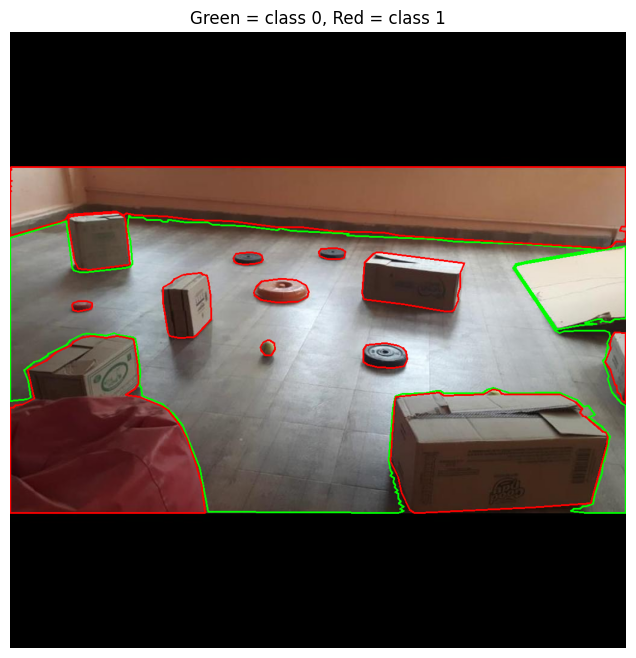

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

old_base = Path("/content/drive/MyDrive/IGVC_dataset_ISRO/additional_dataset/raw/combined_dataset/")
img_path = old_base / "images" / "real_time_192_jpg.rf.a943706b0f65a9932162c8438a078b8a.jpg"
lbl_path = old_base / "labels" / "real_time_192_jpg.rf.a943706b0f65a9932162c8438a078b8a.txt"

img = cv2.imread(str(img_path))
h, w = img.shape[:2]

with open(lbl_path) as f:
    for line in f:
        parts = line.strip().split()
        if not parts:
            continue
        cls_id = int(parts[0])
        coords = np.array(list(map(float, parts[1:]))).reshape(-1, 2)
        coords[:, 0] *= w
        coords[:, 1] *= h
        pts = coords.astype(np.int32)

        color = (0, 255, 0) if cls_id == 0 else (0, 0, 255)  # green=0, red=1
        cv2.polylines(img, [pts], isClosed=True, color=color, thickness=2)

plt.figure(figsize=(8,8))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Green = class 0, Red = class 1")
plt.axis("off")
plt.show()

## Splitting the data, preparing for training

In [ ]:
from pathlib import Path

folder = Path("/content/drive/MyDrive/IGVC_dataset_ISRO/additional_dataset/raw/combined_dataset/images")

# Count all image files (jpg, jpeg, png)
image_count = len([f for f in folder.iterdir() if f.is_file() and f.suffix.lower() in (".jpg", ".jpeg", ".png")])

print(f"Total images: {image_count}")

Total images: 2055


In [ ]:
import shutil
import random
from pathlib import Path

base = Path("/content/drive/MyDrive/IGVC_dataset_ISRO/additional_dataset/raw/combined_dataset")

images_dir = base / "images"
labels_dir = base / "labels"

# --- Create train/val/test subfolders ---
for split in ["train", "val", "test"]:
    (images_dir / split).mkdir(parents=True, exist_ok=True)
    (labels_dir / split).mkdir(parents=True, exist_ok=True)

# --- Gather all images directly in images/ (both jpg and png) ---
all_images = sorted([f for f in images_dir.iterdir() if f.is_file() and f.suffix.lower() in (".jpg", ".png", ".jpeg")])

print(f"Total images found: {len(all_images)}")

random.seed(42)
random.shuffle(all_images)

total   = len(all_images)
n_train = int(total * 0.75)
n_val   = int(total * 0.12)
# remaining ~13% -> test

train_files = all_images[:n_train]
val_files   = all_images[n_train:n_train + n_val]
test_files  = all_images[n_train + n_val:]

def move_pair(img_path, split):
    stem = img_path.stem
    lbl_path = labels_dir / f"{stem}.txt"  # label currently sits flat in labels/

    shutil.move(str(img_path), str(images_dir / split / img_path.name))

    if lbl_path.exists():
        shutil.move(str(lbl_path), str(labels_dir / split / f"{stem}.txt"))
    else:
        (labels_dir / split / f"{stem}.txt").touch()

for f in train_files:
    move_pair(f, "train")
for f in val_files:
    move_pair(f, "val")
for f in test_files:
    move_pair(f, "test")

print("Split done!")
for split in ["train", "val", "test"]:
    imgs = list((images_dir / split).glob("*"))
    lbls = list((labels_dir / split).glob("*.txt"))
    print(f"{split}: {len(imgs)} images, {len(lbls)} labels")

Total images found: 2055
Split done!
train: 1541 images, 1541 labels
val: 246 images, 246 labels
test: 268 images, 268 labels


## Creating yaml file

In [ ]:
from pathlib import Path

yaml_content = """path: /content/drive/MyDrive/IGVC_dataset_ISRO/additional_dataset/raw/Model_2
train: images/train
val: images/val
test: images/test

names:
  0: clean_path
  1: wall_obstacle
"""

yaml_path = Path("/content/drive/MyDrive/IGVC_dataset_ISRO/additional_dataset/raw/Model_2/data.yaml")
with open(yaml_path, "w") as f:
    f.write(yaml_content)

print(f"Saved: {yaml_path}")
print(yaml_content)

Saved: /content/drive/MyDrive/IGVC_dataset_ISRO/additional_dataset/raw/Model_2/data.yaml
path: /content/drive/MyDrive/IGVC_dataset_ISRO/additional_dataset/raw/Model_2
train: images/train
val: images/val
test: images/test

names:
  0: clean_path
  1: wall_obstacle



## Training hte model

In [ ]:
pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.3/41.3 kB 454.7 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 22.2 MB/s eta 0:00:00


In [ ]:
from ultralytics import YOLO

model = YOLO("yolo26n-sem.pt")
path = "/content/drive/MyDrive/IGVC_dataset_ISRO/additional_dataset/raw/Model_2"

results = model.train(
    data=f"{path}/data.yaml",
    epochs=20,
    imgsz=640,
    batch=8,
    project="/content/drive/MyDrive/IGVC_dataset_ISRO/additional_dataset/raw/Model_2/runs",
    name="run_1",
    plots=True,
    val=True,
    # Optimizer config
    optimizer="AdamW",
    lr0=0.0001,
    weight_decay=0.01,
)

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Ultralytics 8.4.71 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/IGVC_dataset_ISRO/additional_dataset/raw/Model_2/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=Non

In [ ]:
from ultralytics import YOLO

model = YOLO("/content/drive/MyDrive/IGVC_dataset_ISRO/additional_dataset/raw/Model_2/runs/run_1/weights/last.pt")
path = "/content/drive/MyDrive/IGVC_dataset_ISRO/additional_dataset/raw/Model_2"

results = model.train(
    data=f"{path}/data.yaml",
    epochs=20,
    imgsz=640,
    batch=8,
    project="/content/drive/MyDrive/IGVC_dataset_ISRO/additional_dataset/raw/Model_2/runs",
    name="run_2",
    plots=True,
    val=True,
    # Optimizer config
    optimizer="AdamW",
    lr0=0.0001,
    weight_decay=0.01,
)

Ultralytics 8.4.71 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/IGVC_dataset_ISRO/additional_dataset/raw/Model_2/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.0001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/drive/MyDrive/IGVC_dataset_ISRO/additional_dataset/raw/Model_2/runs/run_1/weights/last.pt, momentum=0.

## Testing the Model

In [ ]:
from ultralytics import YOLO
model = YOLO("/content/drive/MyDrive/IGVC_dataset_ISRO/runs/run1-2/weights/best.pt")

metrics = model.val(
    data="/content/drive/MyDrive/IGVC_dataset_ISRO/yolo_format_2/igvc.yaml",
    split="test"
)


In [ ]:
from pathlib import Path
from collections import defaultdict

labels_dir = Path("/content/drive/MyDrive/IGVC_dataset_ISRO/additional_dataset/raw/Model_2/labels")

class_names = {
    0: "clean_path",
    1: "wall_obstacle"
}

# Count instances and images per class
instance_counts = defaultdict(int)
image_counts = defaultdict(int)
empty_files = 0

for split in ["train", "val", "test"]:
    split_dir = labels_dir / split
    if not split_dir.exists():
        continue

    for txt_file in split_dir.glob("*.txt"):
        lines = [l.strip() for l in txt_file.read_text().splitlines() if l.strip()]

        if not lines:
            empty_files += 1
            continue

        classes_in_file = set()
        for line in lines:
            cls_id = int(line.split()[0])
            instance_counts[cls_id] += 1
            classes_in_file.add(cls_id)

        for cls_id in classes_in_file:
            image_counts[cls_id] += 1

print("=" * 40)
print(f"{'Class':<20} {'Instances':>10} {'Images':>10}")
print("=" * 40)
for cls_id, name in class_names.items():
    print(f"{name:<20} {instance_counts[cls_id]:>10} {image_counts[cls_id]:>10}")
print("=" * 40)
print(f"Empty label files: {empty_files}")

Class                 Instances     Images
clean_path                 5074       1741
wall_obstacle              2591       1608
Empty label files: 702
